In [20]:
# Importing necessary libraries
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, AnyMessage

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver

from dotenv import load_dotenv

from langgraph.types import Command, interrupt


In [14]:
# Changinf project's name for LangSmith
import os
os.environ['LANGSMITH_PROJECT'] = 'HITL_2'

In [15]:
load_dotenv('.env.chatbot')

True

In [16]:
# Creating model
model = ChatGoogleGenerativeAI(model = 'gemini-2.5-flash')

In [17]:
# Checking response of the model if working or not.
response = model.invoke('Hiii. How are you?')

response

AIMessage(content="Hi there! I'm doing great, functioning perfectly and ready to assist you.\n\nHow about you? How are you doing today?", additional_kwargs={}, response_metadata={'prompt_feedback': {'block_reason': 0, 'safety_ratings': []}, 'finish_reason': 'STOP', 'safety_ratings': []}, id='lc_run--69267fca-6843-4a19-9031-b32c7816cb1c-0', usage_metadata={'input_tokens': 8, 'output_tokens': 28, 'total_tokens': 530, 'input_token_details': {'cache_read': 0}})

In [18]:
# Creating Chat State
class ChatState(MessagesState):
    pass

In [45]:
# C=Defining chat node
def chatnode(state: ChatState):
    messages = state['messages']

    decision = interrupt(
        {
            "type": "approval",
            "reason": "Model is about to answer the question",
            "question": messages[-1].content,
            'instruction': "Approve this request (yes/no)"    #  Our instruction to user.
        }
    )

    if decision['approved'] == 'No'.strip().lower():
        return {'messages': [AIMessage(content = 'Not approved')]}
    else:
        response = model.invoke(messages)
        return {'messages': [response]}

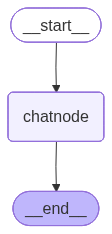

In [46]:
# Creating state graph
graph = StateGraph(ChatState)

# Adding nodes
graph.add_node('chatnode', chatnode)

# Adding edges
graph.add_edge(START, 'chatnode')

chatbot = graph.compile(checkpointer = MemorySaver())

chatbot

In [47]:
# Passing initial input
config = {'configurable': {'thread_id': '1'}}

initial_state = {'messages': 'Explain difference between covariance and correlatiion in simple manner.'}

response = chatbot.invoke(initial_state, config = config)

In [48]:
response

{'messages': [HumanMessage(content='Explain difference between covariance and correlatiion in simple manner.', additional_kwargs={}, response_metadata={}, id='dd29f895-3039-471f-9516-cb8b2d84c671')],
 '__interrupt__': [Interrupt(value={'type': 'approval', 'reason': 'Model is about to answer the question', 'question': 'Explain difference between covariance and correlatiion in simple manner.', 'instruction': 'Approve this request (yes/no)'}, id='1d98ba0ee52d09a96cb5de1f7c0d083a')]}

In [49]:
response['__interrupt__']

[Interrupt(value={'type': 'approval', 'reason': 'Model is about to answer the question', 'question': 'Explain difference between covariance and correlatiion in simple manner.', 'instruction': 'Approve this request (yes/no)'}, id='1d98ba0ee52d09a96cb5de1f7c0d083a')]

In [50]:
interrupt_message = response['__interrupt__'][0].value
interrupt_message

{'type': 'approval',
 'reason': 'Model is about to answer the question',
 'question': 'Explain difference between covariance and correlatiion in simple manner.',
 'instruction': 'Approve this request (yes/no)'}

In [51]:
# Taking user_input

user_input = input(f'''Backend Message: {interrupt_message}
Approve this request(yes/no): ''')

Backend Message: {'type': 'approval', 'reason': 'Model is about to answer the question', 'question': 'Explain difference between covariance and correlatiion in simple manner.', 'instruction': 'Approve this request (yes/no)'}
Approve this request(yes/no):  yes


In [52]:
# Resuming from where stopped
final_response = chatbot.invoke(
    Command(resume = {'approved': user_input}),
    config = config
)

In [56]:
print(final_response['messages'][-1].content)

Let's break it down simply:

Imagine you have two friends, Alice and Bob, who both love watching movies.

**1. Covariance: "Are they moving in the same direction, and how much?"**

*   **What it tells you:**
    *   **Direction:** If Alice watches more movies, does Bob also tend to watch more (positive covariance)? Or does he tend to watch fewer (negative covariance)? Or is there no consistent pattern (covariance near zero)?
    *   **Raw Magnitude:** It gives you a number that indicates *how much* they vary together.
*   **The Problem:** The number itself is hard to interpret.
    *   If you calculate a covariance of "100", is that a strong relationship or a weak one? You don't know!
    *   Why? Because it depends on the *units* you're measuring. If you measured movies watched in "tens of movies" instead of "single movies," the covariance number would change drastically, even if Alice and Bob's viewing habits didn't.
    *   **Analogy:** It's like saying "The building is 100 units ta

# `Next:` Tools with Human-In-The-Loop